# 02_mcmc: fitting the Jansen-Rit model directly to one subject's ERP with NUTS

This notebook fits the Jansen-Rit gain parameters (`g_1`...`g_4`) to a single subject/channel's mean ERP waveform, using NumPyro/NUTS. Unlike Notebook 3 (SBI), there is no summary statistic here: NUTS fits the model's simulated trace against the observed waveform directly, at every step. It
loads its data from what `01_general.ipynb` saved to `data/processed/` and does not touch raw `.mat` files.


Structure:
1. Why MCMC
2. Finding a good set of priors
3. Setting up and running the algorithm
4. Parameter recovery check
5. Running the primary fit
8. Posterior summaries: MAP, pooled posteriors, weighting chains by predictive skill
9. Sampling from the tail of the prior
10. Sweeping channel / time window / frequency filter
11. Fitting of subject/trial-averaged data per condition
12. Fitting a single trial

## Setup

In [1]:
import os
import sys
import time
import warnings
warnings.filterwarnings('ignore')
warnings.simplefilter(action='ignore', category=FutureWarning)

import numpy as np
import xarray as xr

import jax
import jax.numpy as jnp

import numpyro as npr
from numpyro import handlers
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, init_to_value
import numpyro.distributions.transforms as npr_transforms

import arviz as az
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import ipywidgets as widgets
from ipywidgets import Layout, VBox, HBox, Output
from IPython.display import display
from tqdm.auto import tqdm

sys.path.append(os.path.abspath('src'))
import data as dat
import jansen_rit as jrm
import mcmc
import plotting

plotting.apply_house_style()

print('JAX backend:', jax.default_backend())
print('numpyro:', npr.__version__, '| arviz:', az.__version__)

DATA_ROOT = 'data'
PROCESSED_DIR = os.path.join(DATA_ROOT, 'processed')

EASY_MODE = dict(n_warmup=50, n_samples=50, n_chains=4)     # fast run
HARD_MODE = dict(n_warmup=500, n_samples=1000, n_chains=4)  # full run

def mcmc_settings(mode=None, n_warmup=50, n_samples=50, n_chains=4):
    '''
    Return an (n_warmup, n_samples, n_chains) dict.
    mode=None (default): use n_warmup/n_samples/n_chains exactly as given, no capping.
    mode='easy' or 'hard': ignore the given values, cap at the fixed EASY_MODE/HARD_MODE preset instead.
    '''
    if mode is None:
        return dict(n_warmup=n_warmup, n_samples=n_samples, n_chains=n_chains)
    preset = EASY_MODE if mode == 'easy' else HARD_MODE if mode == 'hard' else None
    if preset is None:
        raise ValueError(f"mode must be None, 'easy', or 'hard', got {mode!r}")
    return dict(n_warmup=min(n_warmup, preset['n_warmup']), n_samples=min(n_samples, preset['n_samples']),
                n_chains=min(n_chains, preset['n_chains']))

JAX backend: gpu
numpyro: 0.19.0 | arviz: 0.23.4


**A note `EASY_MODE` vs. `HARD_MODE`**: this notebook runs NUTS around 20 times in total (one real MCMC fit per experiment). 

If `EASY_MODE` is enabled the warmup/samples/chains are capped for that specific run to `(n_warmup=50, n_samples=50, n_chains=4)`.

If `HARD_MODE` is enabled the warmup/samples/chains are put to `(n_warmup=500, n_samples=1000, n_chains=4)`. `HARD_MODE` is enabled for the main fit and the fit to the condition-combined signals (see further).

The mode for a given run can be changed via the ´mode´ input inside the `mcmc_settings function`, if nothing is given this function looks at the other given inputs for `(n_warmup, n_samples, n_chains)`.

### Loading the example ERP

Throughout most of this notebook we fit the Jansen Rit model to one example ERP: channel `example_channel = 4`, ketamine condition, pooled across every subject's ketamine recordings into one grand average (average over trials and subjects). This is the biggest part of what this notebook focuses on.

I chose **channel number 5** (counting starts from 0), because it looked the most like the Jansen Rit simulations from our prior (see Notebook 1). So we have the most chance to get proper fits with this channel, also channel 7 looked like a good option (this is tested later on).

Now we can load this ERP in from storage (see Notebook 1), no raw `.mat` file gets touched.

Important to note is that in all of the following we will only fit the Jansen Rit model to the **time window (0-100 ms)**, this is a shorter window than in Notebook 3, but no good fits could be reached using the long window of (0-500 ms). Later we will also try an even shorter time window of (0-50 ms).

In [2]:
ANES_TYPES = ['keta', 'prop', 'sevo']
erp_datasets = {anes: xr.load_dataarray(os.path.join(PROCESSED_DIR, f'{anes}_all_erps.nc')) for anes in ANES_TYPES}

example_anes = 'keta'
example_channel = 4

keta_time_full, keta_values_full, n_keta_pooled = dat.combine_across_subjects(erp_datasets, [('keta', 'keta')], example_channel)
keta_time, keta_values = mcmc.select_window(keta_time_full, keta_values_full, (0, 100))

## What is MCMC and NUTS

MCMC (Markov Chain Monte Carlo) is a way to draw samples from a distribution you can't write down or solve directly, here the posterior over the model parameters given the data. Instead of solving for the posterior directly, MCMC builds a chain of parameter guesses where each new guess depends only on the current one, where the next guess depends on how well it fits the data. Run long enough, the chain visits parameter values in proportion to how likely they actually are, so summarizing the chain (mean, spread, etc) gives you the posterior.

NUTS (No U Turn Sampler) is the specific MCMC algorithm used here. Plain random walk MCMC wanders inefficiently once you have more than a couple of parameters, so NUTS instead uses the gradient of the fit (how much better or worse things get if a parameter is nudged slightly) to take informed steps. Like a ball rolling through the landscape than a random walk. It automatically figures out how far to roll before it would start turning back on itself and stops there, so it needs very little manual tuning and stays efficient even with several correlated parameters. That's what NumPyro's NUTS sampler is doing under the hood in this notebook.

## Why MCMC (and why this notebook works one subject/channel at a time)

Notebook 3 (SBI) fits a single summary statistic (PCIst) using a neural posterior estimator, trained once on tens of thousands of prior simulations.
Once trained, getting a posterior for a new subject/condition/trial is cheap, which is what makes it practical to run on the whole dataset.

This notebook instead fits the model directly to an observed waveform: at every NUTS step, the model gets simulated forward and compared point by point to the actual ERP trace, through a Gaussian likelihood. That is a much more direct check ("can this model reproduce the actual shape of the response") than a single summary number, but it does not scale the same way. Every subject/channel/condition needs its own NUTS run, which becomes costly.

Two consequences that matter for the rest of this notebook:

- Because the likelihood is on the full waveform, the priors and the observation noise (`sigma_obs` below) need to have approximatly the same     amplitude as the emperical data, not just the general shape. The cell below checks that this is actually the case for our setup.
- Because a single NUTS run here is much cheaper than SBI's simulation budget, this notebook can afford to compare many different fitting configurations side by side. This is what we will do further below.

## Setting up: extra stuff

### A quick amplitude sanity check

`01_general.ipynb` normalizes each subject's ERP amplitude with `amp_scaler=6` before saving (see `data.preprocess_trial_averaged`). The Jansen-Rit model itself, at its default parameters, has a comparable range, so no rescaling is needed.

In [3]:
demo_ts = jnp.arange(-100.0, 500.0, 0.1)
demo_trace = jrm.simulate_erp_temporal(demo_ts, mcmc.DEFAULT_INPUT_PARAMS)  # pure defaults, no free_params override

print(f'JR model default output range:                [{float(demo_trace.min()):.2f}, {float(demo_trace.max()):.2f}]')
print(f'Preprocessed keta grand average range (ch {example_channel + 1}): [{keta_values.min():.2f}, {keta_values.max():.2f}]')

JR model default output range:                [-2.84, 4.88]
Preprocessed keta grand average range (ch 5): [-1.19, 0.87]


### Parameters to fit

For now we only infer the four gain parameters (just like in notebook 3) `g_1`...`g_4` (`jansen_rit.FREE_PARAM_NAMES`), the rest (`delta`, `tau_i`,
`h_i`, `tau_e`, `h_e`, `damping`) stay fixed at `jansen_rit.DEFAULT_PARAMS_TEMPORAL`. Further below we also let the other parameters vary.

The model itself is not redefined here, `jansen_rit.py` already has it (see `jansen_rit.simulate_erp_temporal`), and `01_general.ipynb` already walks
through it. This notebook only adds the NumPyro sampling layer on top, in `src/mcmc.py`.

In [4]:
prm_names = jrm.FREE_PARAM_NAMES
prm_names, jrm.DEFAULT_PARAMS_TEMPORAL

(['g_1', 'g_2', 'g_3', 'g_4'],
 OrderedDict([('g_1', 0.42),
              ('g_2', 0.76),
              ('g_3', 0.15),
              ('g_4', 0.16),
              ('delta', 10.13),
              ('tau_i', 7.77),
              ('h_i', 27.88),
              ('tau_e', 5.77),
              ('h_e', 1.63),
              ('damping', 2.3)]))

### Setting up the fit target

The model is `jansen_rit.simulate_erp_temporal`: a Gaussian pulse input, same as Notebooks 1 and 3, and the same `input_params = (amplitude, width, t0) = mcmc.DEFAULT_INPUT_PARAMS` those notebooks use, so all three are simulating the same physical stimulus.

The pulse is centered at `t0=15` ms with `width=6` ms, so for a stretch of a few tens of ms around `t0` this Gaussian input is non-zero.

The simulation always starts at `x_init = 0` (at rest, physiologically). Far enough before the pulse, `x=0` really is the exact state, so starting there is accurate. But by `t=0` the pulse already has some effect, starting exactly there would force the model to `0` when it should already be slightly off. `burn_in_ms` (`10` ms by default) plants `x_init=0` a bit earlier, at `t=-10`, and lets the model catch up naturally before the fit window begins.

Every fit target in this notebook gets cropped to `(0, 100)` ms right after loading, we only keep the pre-stimulus stretch briefly, to estimate `sigma_obs` from (see further).

`mcmc.make_data_dict` handles this:
- It builds a simulation grid (`ts_sim`, `dt_sim=1.0` ms, RK4, see below) that starts `burn_in_ms` (default 10 ms) before the data's own first time point
- The model simulates on that grid, then drops the burn-in.
- `ds` still works the same as before: every `ds`'th sample of the (now correctly aligned) 1 ms grid is what actually gets compared to the simulation

We fit the grand average ketamine ERP for now, `ds=2` (every other sample of the 1 ms grid, so a fit target roughly every 2 ms).


RK4 at `dt_sim=1.0` ms (the same integrator and step used everywhere in this project now, see `01_general.ipynb`'s "Errors and integrators" section) keeps the discretization error well under `sigma_obs` for every fit in this notebook, even the tightest ones (`sigma_obs` as low as 0.01), so `dt_sim` stays fixed at `1.0` ms throughout.

We estimate and print `sigma_obs` per fit below, just as a characteristic of the data.

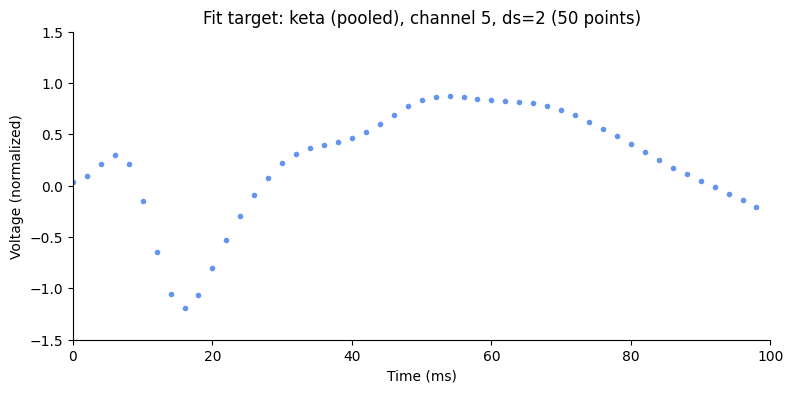

In [5]:
ds = 2
primary_data = mcmc.make_data_dict(keta_time, keta_values, ds=ds)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(primary_data['ts_obs'], primary_data['xpy_obs'], 'o', color=plotting.ANES_COLORS['keta'], markersize=3)
ax.set_xlabel('Time (ms)')
ax.set_ylabel('Voltage (normalized)')
ax.set_title(f"Fit target: keta (pooled), channel {example_channel + 1}, ds={ds} ({primary_data['nt_obs']} points)")
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(0, 100), ylim=(-1.5, 1.5))
plt.show()

### Estimating the observation noise (sigma_obs)

One of the parameters of the MCMC code is `sigma_obs`: this parameter decides how much the data is allowed to scatter around the model's simulated trace at each time point. 

Rather than picking one fixed number by hand and reusing it everywhere, `mcmc.estimate_sigma_obs` reads it straight off the data. From the standard deviation of the pre-stimulus baseline, where there's no evoked response, just noise. 

This comes out smaller for trial-averaged data than for a single trial, so the trial-average fit below and the single-trial fit further down each get a value that actually matches their own noise level instead of sharing one guessed number.

In [6]:
sigma_obs_keta = mcmc.estimate_sigma_obs(keta_time_full, keta_values_full)
sigma_obs_avg = sigma_obs_keta

print(f'sigma_obs, keta (grand average): {sigma_obs_keta:.3f}')

sigma_obs, keta (grand average): 0.039


## Finding a good set of priors

For this MCMC model we need prior sets for the different parameters. We will use 2 different options in this notebook. Both use independent normal distributions truncated to positive values only (`dist.TruncatedNormal(mean, std, low=0)`, gains and other parameters can't physically be negative), mean at each parameter's DCM default, std at 30% of that mean.

### First prior set: varying only the gain parameters

As the first prior set we use the same prior as in Notebook 1 and Notebook 3: we only vary the `g_1..g_4`.

In [7]:
prior_specs = mcmc.get_prior_specs()  # g_1..g_4 only, for now
prior_specs

{'g_1': (0.42, 0.126),
 'g_2': (0.76, 0.22799999999999998),
 'g_3': (0.15, 0.045),
 'g_4': (0.16, 0.048)}

Given this first set of priors and the estimated `sigma_obs`, we can construct the MCMC model.

In [8]:
model = mcmc.build_model(sigma=sigma_obs_avg)
model

<function mcmc.build_model.<locals>.model(data, prior_specs, sigma_obs=0.039252110503704175)>

### Second prior set: also varying the other parameters
Same normal construction, just applied to every parameter in `jansen_rit.PARAM_NAMES_TEMPORAL` instead of only `FREE_PARAM_NAMES`

This prior set will be used in the "Does letting everything vary help?" section further down. Running that fit is expensive enough (10 free
parameters instead of 4).

In [9]:
prior_specs_all = mcmc.get_prior_specs(jrm.PARAM_NAMES_TEMPORAL)
model_all = mcmc.build_model(jrm.PARAM_NAMES_TEMPORAL)
prior_specs_all

{'g_1': (0.42, 0.126),
 'g_2': (0.76, 0.22799999999999998),
 'g_3': (0.15, 0.045),
 'g_4': (0.16, 0.048),
 'delta': (10.13, 3.039),
 'tau_i': (7.77, 2.331),
 'h_i': (27.88, 8.363999999999999),
 'tau_e': (5.77, 1.7309999999999999),
 'h_e': (1.63, 0.48899999999999993),
 'damping': (2.3, 0.69)}

### A quick sanity check

Now we perform a quick check where we run the model function under a fixed seed and where we check if the shape of every variable it creates (g_1, g_2, ..., the data plate, xpy_) is the same.

In [10]:
with handlers.seed(rng_seed=1):
    trace = handlers.trace(model).get_trace(primary_data, prior_specs, 2.0)
print(npr.util.format_shapes(trace))

Trace Shapes:     
 Param Sites:     
Sample Sites:     
     g_1 dist    |
        value    |
     g_2 dist    |
        value    |
     g_3 dist    |
        value    |
     g_4 dist    |
        value    |
   data plate 50 |
    xpy_ dist 50 |
        value 50 |


## Setting up and running the algorithm

The MCMC algorithm has a few inputs that control how it runs:

- `target_accept_prob` says "how carefully to step." At each step, NUTS proposes a move and then decides whether to accept it, based on how well it matches the true underlying trajectory. This setting is the target fraction of proposals that should get accepted, usually somewhere around 0.8 to 0.95. If we set it too low then the sampler takes big, careless steps that get rejected a lot, wasting effort and possibly missing narrow regions of high probability. If we set it too high and the sampler creeps along in tiny, overly cautious steps, technically accurate but slow to explore the full posterior. It's a dial between speed and carefulness.

- `max_tree_depth` says "how far to look before giving up." NUTS builds each step by exploring outward, doubling how far it looks each time, until it detects it would start curving back toward where it came from (the "no U-turn" part). This setting caps how many doubling rounds it's allowed to do per step. If the true trajectory needs more room to explore than this cap allows, the sampler gets cut off early and each step ends up shorter and less informative than it should be, though the run itself won't crash, it'll just be less efficient. If it's set too high, individual steps can become expensive to compute since the sampler is allowed to explore much further before stopping.

- `sigma` says how much the observed data is expected to scatter around the model's simulated trace at each time point, in other words, how noisy the data is assumed to be. This isn't a knob that changes how the sampler moves, it's part of the model itself, the Gaussian likelihood comparing the simulated waveform to the real one at every timepoint. A small `sigma` tells the model "the data should sit very close to the simulated curve," which makes the fit strict and can make the posterior overconfident if the real data is actually noisier than assumed. A large `sigma` is more forgiving, letting the model accept a wider range of parameter values since even a mediocre fit still counts as plausible given how much scatter is allowed.


I made `mcmc.kernel_preset` to have two possible NUTS configurations:

| | `'default'` | `'lower_accept'` |
|---|---|---|
| `target_accept_prob` | 0.75 | 0.6 |
| `max_tree_depth` | 14 | 12 |
| starting point | random draw from the prior, independent per chain | random draw from the prior, independent per chain |

In plain terms:
- `'default'` is the general purpose option, used for the real fits and most sweep configs below. It takes moderately careful steps and is allowed to look fairly far ahead before giving up (`max_tree_depth=14`).
- `'lower_accept'` is the looser, faster alternative (lowest `target_accept_prob`), useful as a quick check or when `'default'` is taking too long.

In both configurations, every chain gets its own random start instead of all starting at the same point. This is because starting every chain at the exact same value makes R-hat a weaker check, chains launched from one spot are more likely to agree with each other (or get stuck together) even if the posterior secretly has more than one region worth visiting.

`QUICK_MODE` (set in the setup cell) shrinks n_warmup/n_samples/n_chains for every run in this notebook, so we can iterate fast. mcmc_settings(...) calls below always pass the real, intended values, `QUICK_MODE` just caps them behind the scenes while it's on.

Before turning it off, keep in mind that full runs will be noticeably slower. 

In [11]:
settings = mcmc_settings(mode='hard', n_warmup=500, n_samples=1000, n_chains=4)
settings

{'n_warmup': 500, 'n_samples': 1000, 'n_chains': 4}

- `n_warmup`: the iterations at the start that get thrown away afterwards. NUTS uses them to tune itself (step size, mass matrix) to the shape of this particular posterior, none of these draws count towards the actual result.
- `n_samples`: the draws per chain that are actually kept after warmup. These make up the posterior we look at in every plot below.
- `n_chains`: how many independent copies of the sampler get run. Comparing chains against each other (R-hat, the trace plots further down) is how we check the result can be trusted: if every chain lands in the same place, that is a good sign. If they disagree, this is probalby because of multimodality of the model.

## Parameter recovery check

Now we will perform a parameter recovery check. This means that we will sample a set of parameter values from the prior, then we will simulate the corresponding signal. After which we add some gaussian noise on top of it (`sigma_obs_avg`). 

And given this simulated true signal (with known true parameter values), we will try to fit a completely new simulation to it. To see whether or not we get the correct parameter values in the end.

The true parameters are drawn at random from the prior.

In [12]:
true_param_key = jax.random.PRNGKey(42)
true_param_keys = jax.random.split(true_param_key, len(prior_specs))
true_free_params = {name: float(dist.TruncatedNormal(mean, std, low=0.0).sample(key))
                     for (name, (mean, std)), key in zip(prior_specs.items(), true_param_keys)}

print('Sampled parameter values', true_free_params)

Sampled parameter values {'g_1': 0.42963042855262756, 'g_2': 0.8981943726539612, 'g_3': 0.16947147250175476, 'g_4': 0.14650186896324158}


Given these prior samples, we can simulate the signal, and add some gaussian noise.

In [13]:
recovery_trace_clean = np.asarray(mcmc.simulate_on_data_grid(primary_data, true_free_params))
recovery_time = np.asarray(primary_data['ts_obs'])

recovery_noise_rng = np.random.default_rng(0)
recovery_values = recovery_trace_clean + recovery_noise_rng.normal(0, sigma_obs_avg, size=recovery_trace_clean.shape)
recovery_data = mcmc.make_data_dict(recovery_time, recovery_values, ds=1)

Now we can plot the resulting simulated target with noise.

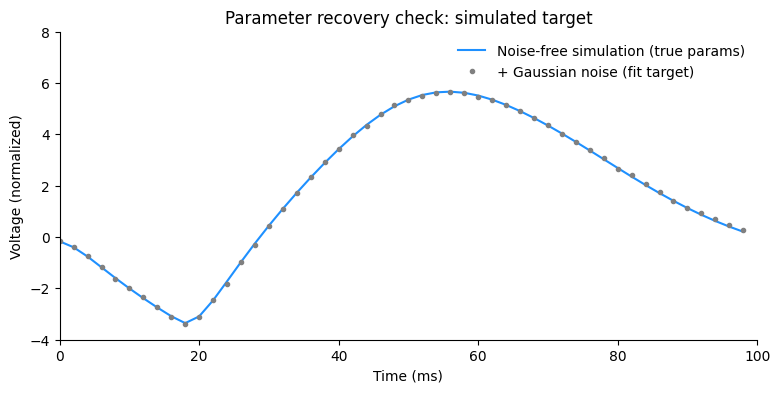

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(recovery_time, recovery_trace_clean, color='dodgerblue', lw=1.5, label='Noise-free simulation (true params)')
ax.plot(recovery_time, recovery_values, 'o', color='gray', markersize=3, label='+ Gaussian noise (fit target)')
ax.set_xlabel('Time (ms)')
ax.set_ylabel('Voltage (normalized)')
ax.set_title('Parameter recovery check: simulated target')
ax.legend(frameon=False)
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(float(recovery_time.min()), 100))
plt.show()

Now we can run the MCMC algorithm.

In [15]:
recovery_key = jax.random.PRNGKey(7)
recovery_settings = mcmc_settings(mode='easy', n_warmup=50, n_samples=50, n_chains=4)
recovery_mcmc, recovery_elapsed = mcmc.run_nuts(
    model, recovery_data, prior_specs, recovery_key, sigma_obs=sigma_obs_avg,
    kernel_kwargs=mcmc.kernel_preset('default'), **recovery_settings)

sample: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:42<00:00,  2.35it/s]

NUTS took 48.4 sec

                mean       std    median      5.0%     95.0%     n_eff     r_hat
       g_1      0.45      0.02      0.44      0.42      0.48     68.90      1.02
       g_2      0.90      0.00      0.90      0.89      0.90     88.61      0.99
       g_3      0.16      0.03      0.16      0.12      0.22     37.76      1.12
       g_4      0.16      0.03      0.15      0.11      0.20     35.88      1.13

Number of divergences: 0


Now let's plot the  posterior resuls + the chains, where the "reference value" refers to the originally sampled parameter set (ground truth):

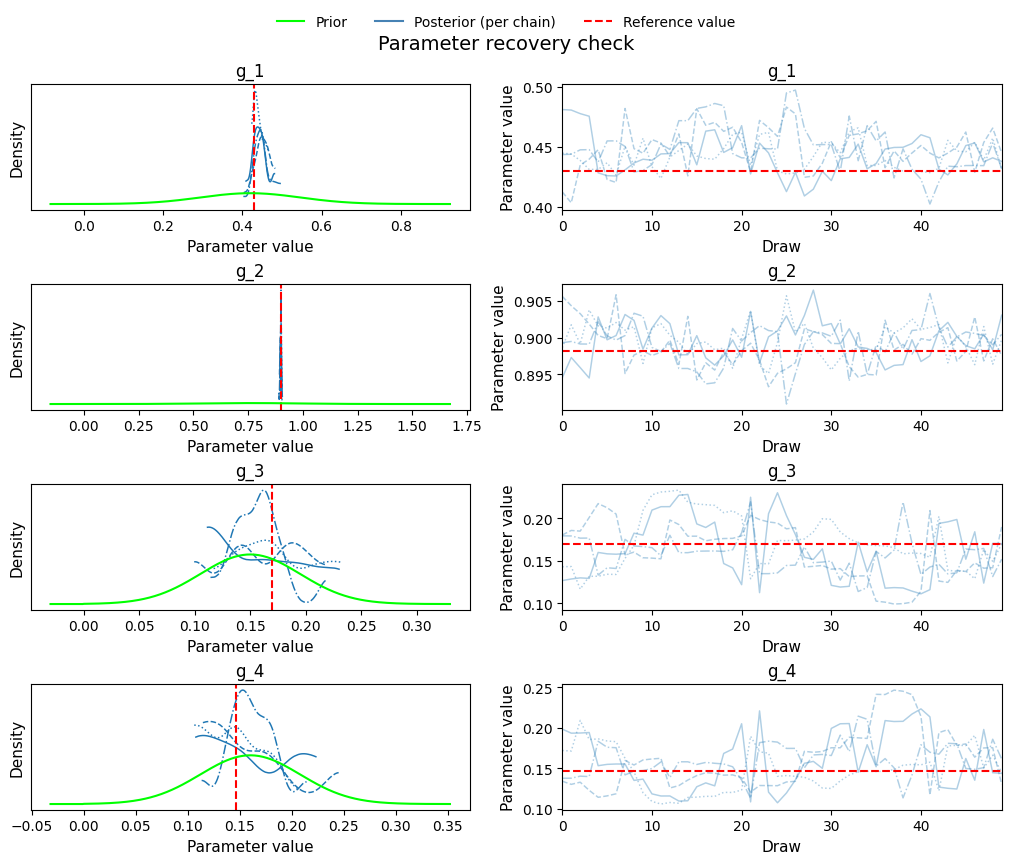

In [16]:
recovery_az = az.from_numpyro(recovery_mcmc)
true_theta_list = [true_free_params[p] for p in prm_names]

fig, axes = plotting.plot_trace_with_prior(recovery_az, prm_names, prior_specs, theta_ref=true_theta_list,
                                            title='Parameter recovery check')
plt.show()

And now we can sample some parameter sets from the posterior, and simulate their signal, to compare it to the original signal.

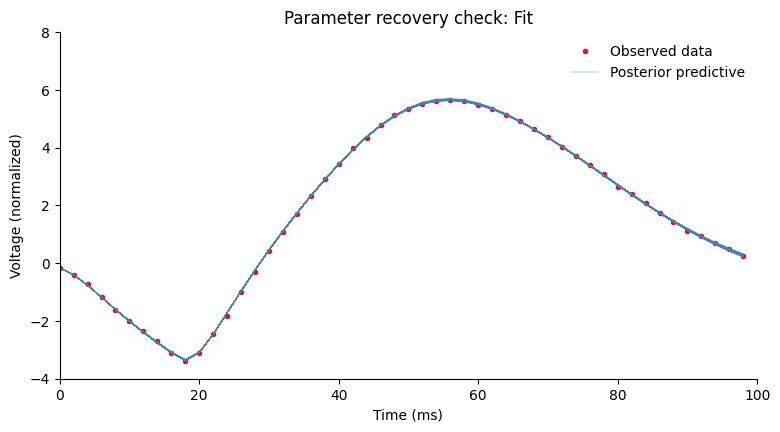

In [17]:
recovery_post_pred = mcmc.sample_posterior_predictive(model, recovery_data, prior_specs, recovery_mcmc.get_samples(), sigma_obs=sigma_obs_avg)
fig, ax = plt.subplots(figsize=(9, 4.5))
plotting.plot_predictive_overlay(ax, recovery_data['ts_obs'], recovery_data['xpy_obs'], recovery_post_pred['xpy_model'],
                                  title='Parameter recovery check: Fit', xlim=(0, 100))
plt.show()

A proper fit is reached!

## Running the primary fit

Now we can try to fit the jansen Rit simulations to the following emperical ERP:

- Ketamine, channel 5 (`region=4`), pooled across every subject and trial, `ds=2`.


For this we will use the `'default'` kernel.

In [18]:
rng_key = jax.random.PRNGKey(0)

In [19]:
primary_mcmc, primary_elapsed = mcmc.run_nuts(
    model, primary_data, prior_specs, rng_key, sigma_obs=sigma_obs_avg,
    kernel_kwargs=mcmc.kernel_preset('default'), **settings)

sample: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████| 1500/1500 [02:55<00:00,  8.54it/s]


NUTS took 178.0 sec

                mean       std    median      5.0%     95.0%     n_eff     r_hat
       g_1      0.06      0.05      0.04      0.00      0.12   1957.11      1.00
       g_2      0.16      0.00      0.16      0.15      0.16   2173.42      1.00
       g_3      0.11      0.03      0.11      0.06      0.17   1252.03      1.00
       g_4      0.12      0.04      0.12      0.06      0.18   1351.33      1.00

Number of divergences: 0


## Extracting results

In the above print and the plots below, there are certain quantities which are really important to keep an eye on. Namely the following:

- The **Gelman-Rubin statistic** ($\hat R$) measures within- vs. between-chain convergence, values close to 1 indicate good convergence, above roughly 1.1 is usually taken as a sign the chains have not converged to each other.


- **Divergences** are NUTS flagging a numerical problem with a proposed step, ideally there are none. 


Both are printed in the summary above, the cell below plots the log joint density per chain, another view of the same thing:

- `lp = -potential_energy` is the log posterior density (prior + likelihood, up to a constant) at each sampled draw. The absolute value isn't  meaningful on its own. What actually matters is:

    -  **within a chain**: does the trace settle into a stable band after warmup and stay there (good), or does it keep drifting/trending (still moving
  towards equilibrium, needs more warmup)? 
    - **across chains**: do the different chains' bands sit at roughly the same height (good, they've converged to the same region), or does one chain
  sit persistently higher/lower than another (bad, it's stuck somewhere less probable and hasn't mixed with the others, same information $\hat R$
  gives numerically)?

The dashed line in each chain marks that chain's mean lp, so the quickest read of the plot is whether those dashed lines line up across chains.


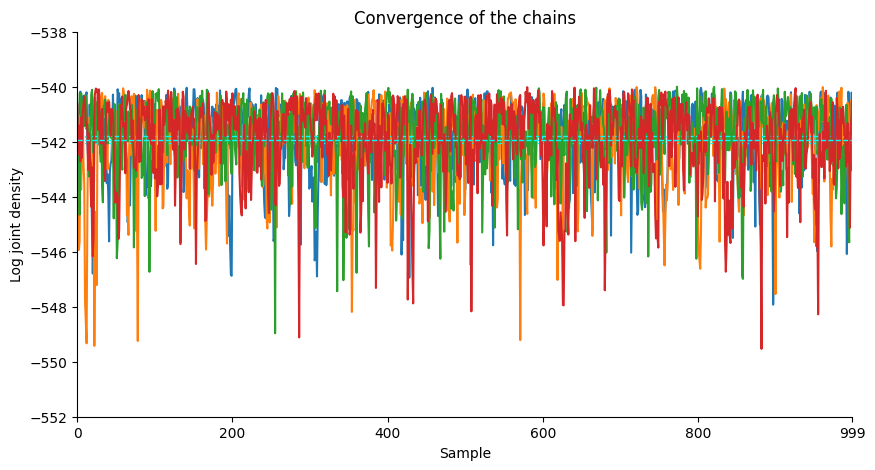

In [20]:
lp = -np.asarray(primary_mcmc.get_extra_fields()['potential_energy'])
fig, ax = plotting.plot_convergence(lp, settings['n_samples'], settings['n_chains'])
plt.show()

Trace plot with the normal prior overlaid and the JR model's default parameter values marked as a reference (not a literal ground truth for real data, real neural data has no known "true" gain values).

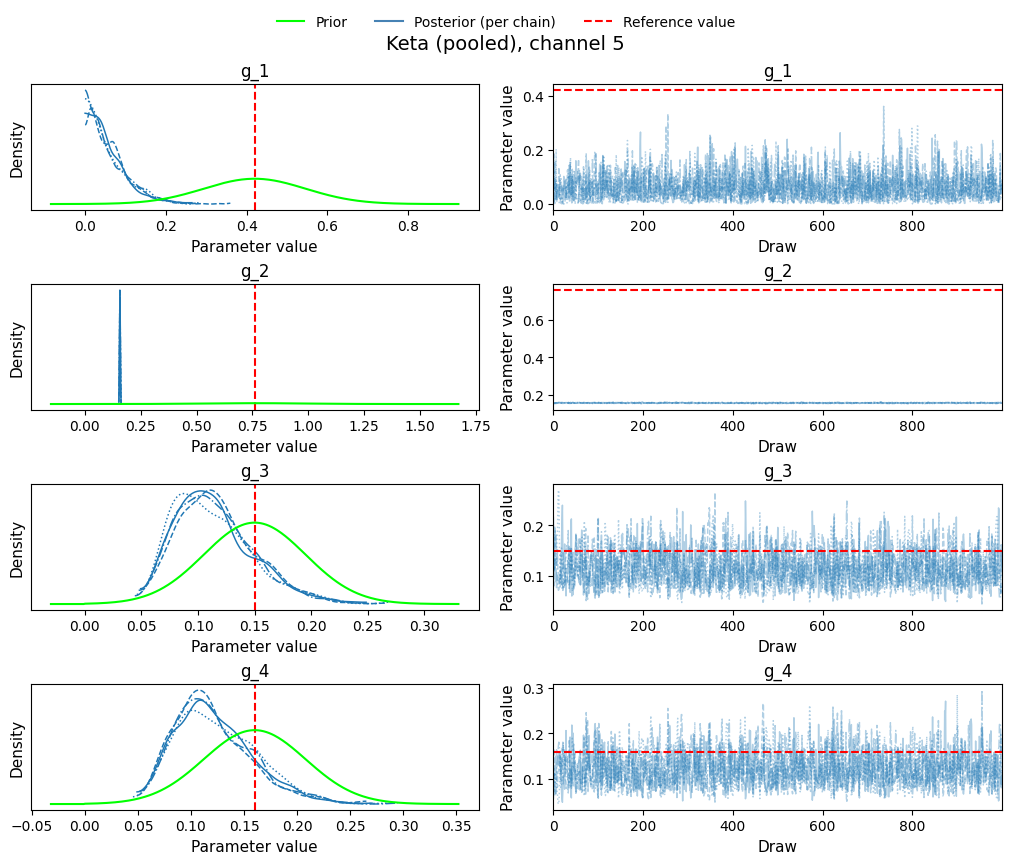

In [21]:
primary_az = az.from_numpyro(primary_mcmc)
theta_ref = [jrm.DEFAULT_PARAMS_TEMPORAL[p] for p in prm_names]

fig, axes = plotting.plot_trace_with_prior(primary_az, prm_names, prior_specs, theta_ref=theta_ref,
                                            title=f'Keta (pooled), channel {example_channel + 1}')
plt.show()


### Posterior predictive check

Now  we can sample some prior sets from the posteriors and see if the simulations following from these samples overlap with the emperical data.
Each thin line is one of the posterior draw's simulated trace.

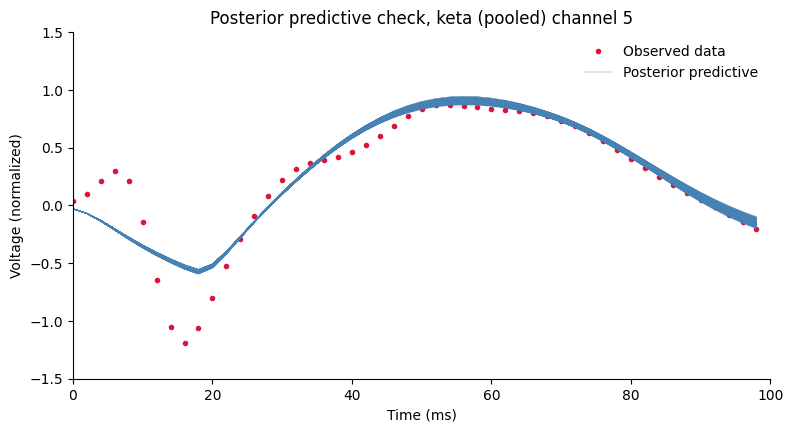

In [22]:
post_pred = mcmc.sample_posterior_predictive(model, primary_data, prior_specs, primary_mcmc.get_samples(), sigma_obs=sigma_obs_avg)
fig, ax = plt.subplots(figsize=(9, 4.5))
plotting.plot_predictive_overlay(ax, primary_data['ts_obs'], primary_data['xpy_obs'], post_pred['xpy_model'],
                                  title=f'Posterior predictive check, keta (pooled) channel {example_channel + 1}',
                                  xlim=(0, 100))
plt.show()

This fit looks relativaly good! Only the beginning is not super clean.

## Combining posteriors from different chains

In this MCMC algorithm we use different chains, meaning that we end up with different posteriors for a given emperical signal.

We have different options of combining the posteriors from these different chains into one global posterior.

### Option 1: equal weigth per chain

The first option is the simplest: we pool every chain's draws together (equal weight per chain) and look at the combined distribution per parameter.

Then we also plot the MAP value: the single parameter value sitting at the peak of the posterior. This is calculated per parameter independently, not a true joint optimization over all four parameters at once.

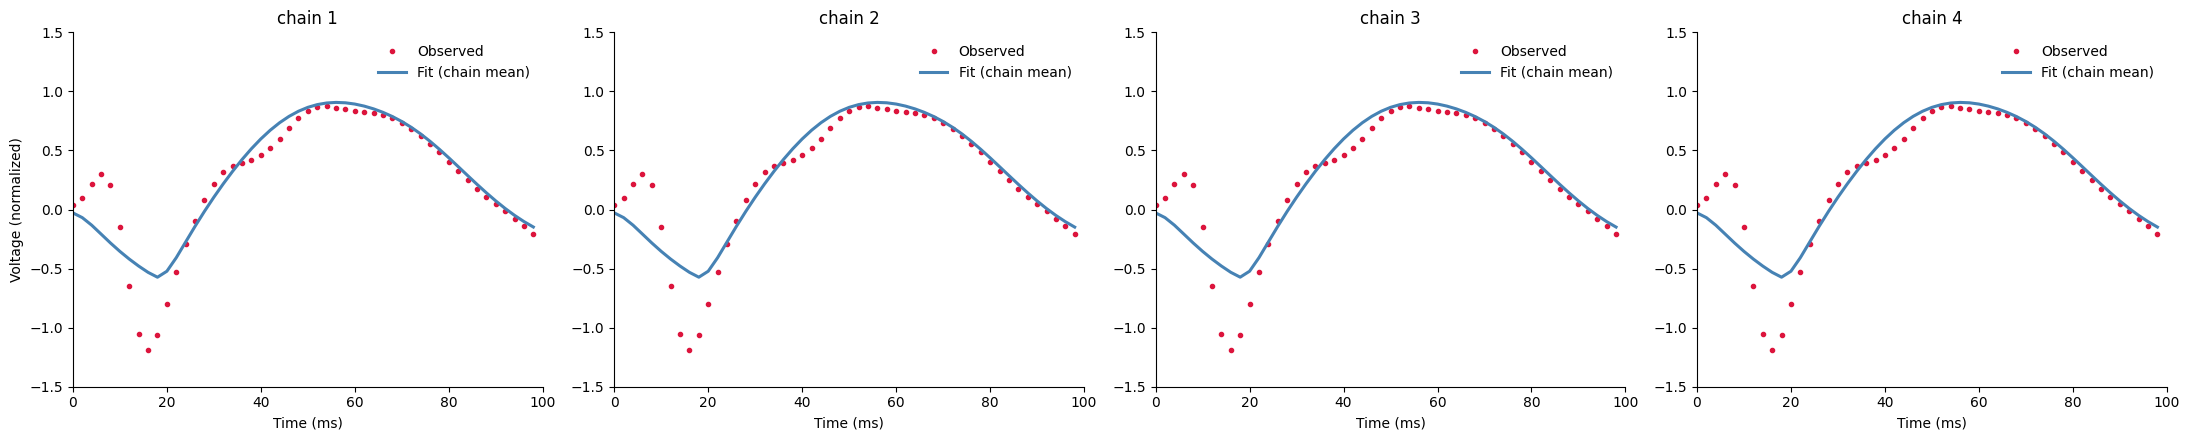

In [23]:
fig, ax = plotting.plot_fitted_per_chain(primary_data, primary_az.posterior, xlim=(0, 100))
plt.show()

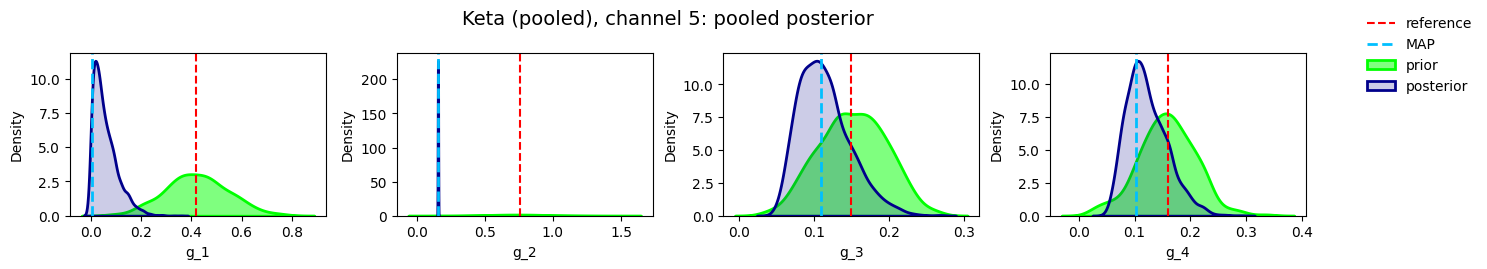

In [24]:
n_params = len(prm_names)
chains_pooled = primary_az.posterior[prm_names].to_array().values.reshape(n_params, -1)
params_map = mcmc.compute_map(chains_pooled)

prior_predictions = mcmc.sample_prior_predictive(model, primary_data, prior_specs, n_prior=500, sigma_obs=sigma_obs_avg)

fig, ax = plotting.plot_pooled_posterior(prm_names, prior_predictions, chains_pooled, params_map, theta_ref=theta_ref,
                                          title=f'Keta (pooled), channel {example_channel + 1}: pooled posterior')
plt.show()

### Option 2: Weighting chains by predictive skill

The pooled posterior above weights every chain equally. If chains actually disagree (some found a better fit than others), we can introduce weighing based on each chain's expected log predictive density (`arviz.compare(...,method='stacking')`).

`mcmc.stack_chains_by_elpd` does this: splits the InferenceData into one object per chain, computes stacking weights, and returns the weighted pooled draws.

stacking weights (one per chain): [1.00000000e+00 0.00000000e+00 3.33066907e-16 5.86336535e-16]


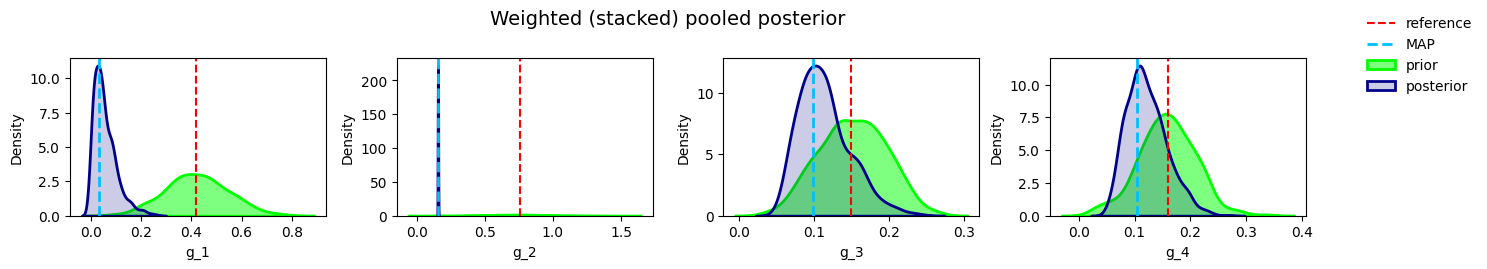

In [25]:
chains_stacked, stack_weights = mcmc.stack_chains_by_elpd(primary_az, prm_names, settings['n_chains'])
print('stacking weights (one per chain):', stack_weights)

params_map_stacked = mcmc.compute_map(chains_stacked)
fig, ax = plotting.plot_pooled_posterior(prm_names, prior_predictions, chains_stacked, params_map_stacked, theta_ref=theta_ref,
                                          title='Weighted (stacked) pooled posterior')
plt.show()

If the weights above end up close to uniform (`1/n_chains` each), stacking isn't finding a reason to prefer one chain over another. The weighting didn't change the picture.

In the following we stick to option 1. Because if the chains converge, they should in the end give all the same posteriors anyway. In standard MCMC algorithms option 1 is usually chosen.

## Sampling from the tail of the prior

Now we try a different idea: we start from somewhere the prior considers unlikely (the outer 2.5% tails of the prior predictive distribution) instead of just anywhere in it. To see if that helps a chain escape whatever mode it otherwise keeps landing in.

`mcmc.low_prob_sample` picks one such tail value per parameter.

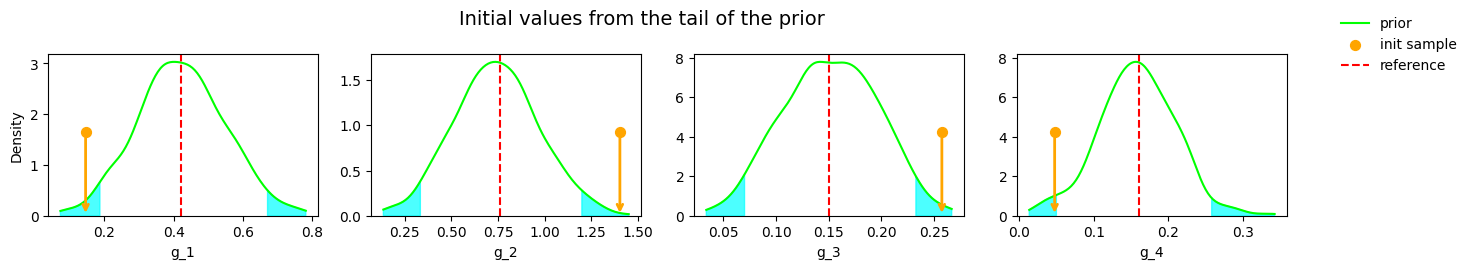

In [26]:
tail_rng = np.random.default_rng(0)
prior_q, tail_sample_vals, quantile_bounds = mcmc.low_prob_sample(prm_names, prior_predictions, rng=tail_rng)

fig, ax = plotting.plot_prior_tail(prm_names, theta_ref, prior_q, tail_sample_vals, quantile_bounds)
plt.show()

Before running the MCMC algorithm on this sampled parameter set, let's first check what the amplitude range is of this simulation. 

To guarantee that it doesn't blow up.

In [27]:
tail_init = {name: float(val) for name, val in zip(prm_names, tail_sample_vals)}
tail_kernel_kwargs = dict(target_accept_prob=0.75, max_tree_depth=14, adapt_step_size=True,
                           init_strategy=init_to_value(values=tail_init))

tail_free_params = dict(zip(prm_names, tail_sample_vals))
tail_trace = mcmc.simulate_on_data_grid(primary_data, tail_free_params)
print('tail init parameter values:', tail_free_params)
print(f'simulated trace range at the tail init: [{float(tail_trace.min()):.3g}, {float(tail_trace.max()):.3g}] (data range is roughly [-6, 6])')

tail init parameter values: {'g_1': np.float64(0.14559995531370487), 'g_2': np.float64(1.403839773684961), 'g_3': np.float64(0.2575103023072594), 'g_4': np.float64(0.047422402215150546)}
simulated trace range at the tail init: [-5.12, 7.06] (data range is roughly [-6, 6])


These ranges look good. Now we can procede with the simulation part.

sample: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:29<00:00,  3.39it/s]


NUTS took 45.4 sec

                mean       std    median      5.0%     95.0%     n_eff     r_hat
       g_1      0.05      0.05      0.04      0.00      0.12     71.43      1.01
       g_2      0.16      0.00      0.16      0.15      0.16    167.29      1.00
       g_3      0.11      0.03      0.11      0.07      0.17     62.41      1.08
       g_4      0.12      0.04      0.12      0.07      0.18     52.74      1.09

Number of divergences: 0


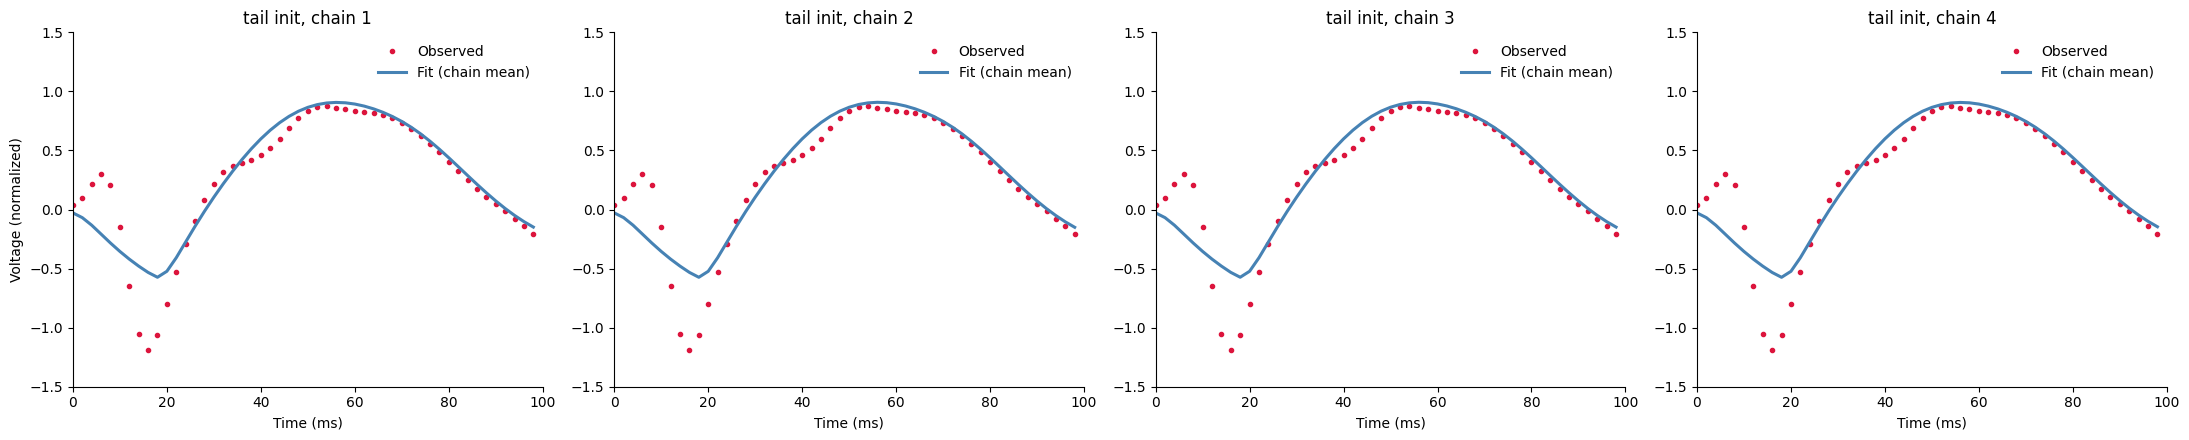

In [28]:
tail_settings = mcmc_settings(mode='easy', n_warmup=50, n_samples=50, n_chains=4)

rng_key, tail_key = jax.random.split(rng_key)
try:
    tail_mcmc, tail_elapsed = mcmc.run_nuts(model, primary_data, prior_specs, tail_key, sigma_obs=sigma_obs_avg,
                                              kernel_kwargs=tail_kernel_kwargs, **tail_settings)
    tail_az = az.from_numpyro(tail_mcmc)
    fig, ax = plotting.plot_fitted_per_chain(primary_data, tail_az.posterior, title_prefix='tail init, ', xlim=(0, 100))
    plt.show()
except RuntimeError as e:
    print(f'NUTS could not even initialize from this tail sample: {e}')

Comparing this fit to the primary run's fitted-per-chain plot above, starting from an unlikely point isn't resulting in a different result ): .

## Does letting everything vary help?

Back to `model_all` and `prior_specs_all` from the priors section: the same
model, normal priors, but sampling all 10 parameters in
`jansen_rit.PARAM_NAMES_TEMPORAL` instead of just `g_1..g_4`. Ten free
parameters means a much bigger, harder to explore space, so this gets one
run and a direct comparison to the g-only fit above, not the full
diagnostic suite.

In [29]:
all_settings = mcmc_settings(mode='easy', n_warmup=50, n_samples=50, n_chains=4)


rng_key, all_key = jax.random.split(rng_key)
all_mcmc, all_elapsed = mcmc.run_nuts(model_all, primary_data, prior_specs_all, all_key, sigma_obs=sigma_obs_avg,
                                        kernel_kwargs=mcmc.kernel_preset('default', jrm.PARAM_NAMES_TEMPORAL), **all_settings)


sample: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:46<00:00,  2.13it/s]

NUTS took 50.8 sec

                mean       std    median      5.0%     95.0%     n_eff     r_hat
   damping      1.77      0.05      1.77      1.70      1.85    248.87      1.00
     delta     17.08      0.47     17.12     16.22     17.72    254.06      0.99
       g_1      0.38      0.10      0.36      0.22      0.53     51.39      1.08
       g_2      2.05      0.18      2.06      1.82      2.40    184.22      1.02
       g_3      0.27      0.03      0.27      0.22      0.31    144.81      0.99
       g_4      0.28      0.03      0.28      0.23      0.34     91.90      0.99
       h_e      0.20      0.01      0.20      0.18      0.22    204.66      1.01
       h_i     50.51      5.60     50.78     41.24     59.17    143.17      0.99
     tau_e      4.74      0.11      4.74      4.59      4.95    254.12      1.00
     tau_i     20.59      0.87     20.55     19.37     22.06    238.13      1.00

Number of divergences: 0


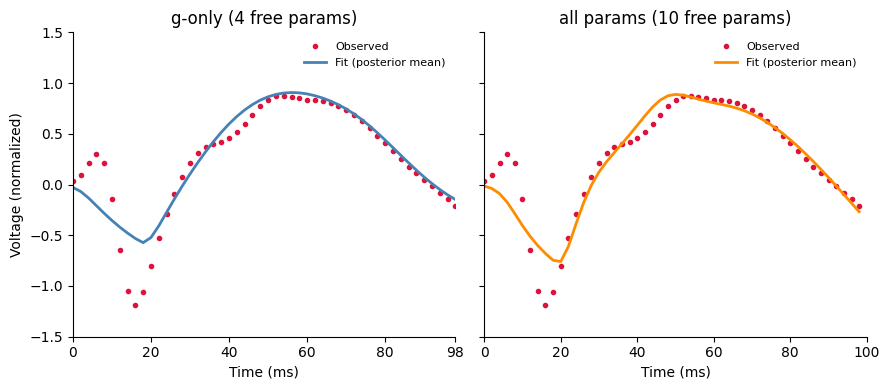

In [30]:
all_az = az.from_numpyro(all_mcmc)

fig, ax = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
ax[0].plot(primary_data['ts_obs'], primary_data['xpy_obs'], 'o', color='crimson', markersize=3, label='Observed')
ax[0].plot(primary_data['ts_obs'], primary_az.posterior['xpy_model'].values.reshape(-1, primary_data['nt_obs']).mean(axis=0),
           lw=2, color='steelblue', label='Fit (posterior mean)')
ax[0].set_title(f'g-only ({len(prm_names)} free params)')
ax[0].set_xlabel('Time (ms)')
ax[0].set_ylabel('Voltage (normalized)')
ax[0].legend(fontsize=8, frameon=False)
plotting.modify_axis_spines(ax[0], which=['x', 'y'], xlim=(float(primary_data['ts_obs'].min()), float(primary_data['ts_obs'].max())))

ax[1].plot(primary_data['ts_obs'], primary_data['xpy_obs'], 'o', color='crimson', markersize=3, label='Observed')
ax[1].plot(primary_data['ts_obs'], all_az.posterior['xpy_model'].values.reshape(-1, primary_data['nt_obs']).mean(axis=0),
           lw=2, color='darkorange', label='Fit (posterior mean)')
ax[1].set_title(f'all params ({len(jrm.PARAM_NAMES_TEMPORAL)} free params)')
ax[1].set_xlabel('Time (ms)')
ax[1].legend(fontsize=8, frameon=False)
plotting.modify_axis_spines(ax[1], which=['x', 'y'], xlim=(0, 100))

fig.tight_layout()
plt.show()


Letting `delta`/`tau_i`/`h_i`/`tau_e`/`h_e`/`damping` vary too gives the model a lot more freedom to match the waveform's amplitude and shape. This results in a better fit.


But in the rest of this notebook we only let the g-parameters vary. This is to keep the results consistent/comparable with Notebook 3 and because letting everything vary may lead to results which are difficult to physically explain.

## Sweeping channel, time window, and frequency filter

From here on, the same fit gets re-run under different conditions to see if anything helps: a different channel, a different kernel, a shorter time window, a low-pass filtered version of the signal.

Each configuration below is one dict: which channel/condition, an optional time window (falls back to the full preprocessed `[0, 100]` ms range, whether to low-pass filter first (`mcmc.apply_lowpass`), and which kernel/chain settings to use. Every config pools across subjects the same way the primary keta grand average does (`dat.combine_across_subjects`).

Before running any of these, we plot the different configurations: channel 7 is a genuinely different trace, the "basic" channel 4 keta trace is literally the same keta_time/keta_values grand average used as the primary fit target, and the short window/lowpass versions are that same channel 4 trace cropped or filtered.

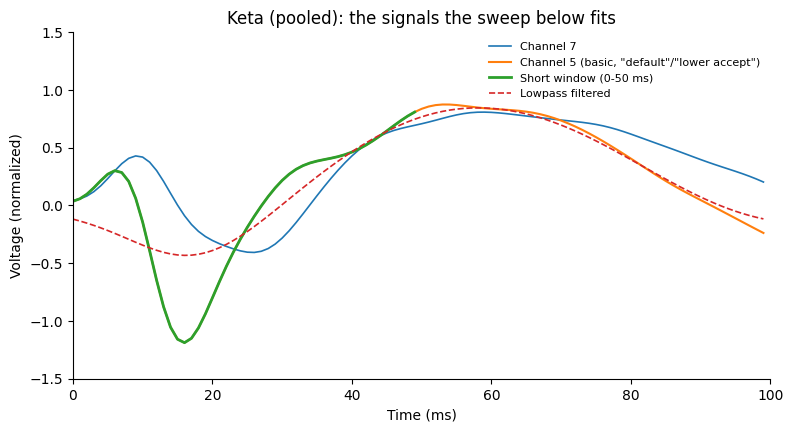

In [31]:
sweep_ch7_t_full, sweep_ch7_v_full, _ = dat.combine_across_subjects(erp_datasets, [(example_anes, example_anes)], 6)
sweep_ch7_t, sweep_ch7_v = mcmc.select_window(sweep_ch7_t_full, sweep_ch7_v_full, (0, 100))
sweep_short_t, sweep_short_v = mcmc.select_window(keta_time, keta_values, (0, 50))
sweep_lowpass_v = mcmc.apply_lowpass(keta_values, cutoff_hz=20, fs=1000)


fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(sweep_ch7_t, sweep_ch7_v, lw=1.2, label='Channel 7')
ax.plot(keta_time, keta_values, lw=1.5, label=f'Channel {example_channel + 1} (basic, "default"/"lower accept")')
ax.plot(sweep_short_t, sweep_short_v, lw=2, label='Short window (0-50 ms)')
ax.plot(keta_time, sweep_lowpass_v, lw=1.2, ls='--', label='Lowpass filtered')
ax.set_xlabel('Time (ms)')
ax.set_ylabel('Voltage (normalized)')
ax.set_title(f'Keta (pooled): the signals the sweep below fits')
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(0, 100), ylim=(-1.5, 1.5))
ax.legend(frameon=False, fontsize=8)
plt.show()

In [32]:
sweep_configs = [
    dict(name='channel 7',   channel=6, condition='keta',        window=(0, 100),      lowpass=False, ds=2, kernel='default'),
    dict(name='Kernel: lower accept', channel=4, condition='keta',       window=(0, 100),   lowpass=False, ds=2, kernel='lower_accept'),
    dict(name='short window', channel=4, condition='keta',       window=(0, 50),   lowpass=False, ds=1, kernel='default'),
    dict(name='lowpass',     channel=4, condition='keta',        window=(0, 100),      lowpass=True,  ds=2, kernel='default'),
]
len(sweep_configs)

4

In [33]:
def run_sweep_config(cfg, rng_key):
    '''Build the data dict for one sweep config, run NUTS, return (data, mcmc, az_post, sigma_obs).'''
    t, v, _ = dat.combine_across_subjects(erp_datasets, [(example_anes, cfg['condition'])], cfg['channel'])
    if cfg['lowpass']:
        v = mcmc.apply_lowpass(v, cutoff_hz=20, fs=1000)
        
    # estimate sigma_obs from this (possibly filtered) trace's own baseline, before any window cropping below
    sigma_obs_cfg = mcmc.estimate_sigma_obs(t, v)
    if cfg['window'] is not None:
        t, v = mcmc.select_window(t, v, cfg['window'])
    # dt_sim stays at the default (1.0 ms, RK4) regardless of sigma_obs, see 01_general.ipynb
    cfg_data = mcmc.make_data_dict(t, v, ds=cfg['ds'])

    settings_cfg = mcmc_settings(mode='easy', n_warmup=cfg.get('n_warmup', 50), n_samples=cfg.get('n_samples', 50),
                                  n_chains=cfg.get('n_chains', 4))
    kernel_kwargs = mcmc.kernel_preset(cfg['kernel'])
    cfg_mcmc, cfg_elapsed = mcmc.run_nuts(model, cfg_data, prior_specs, rng_key, sigma_obs=sigma_obs_cfg,
                                            kernel_kwargs=kernel_kwargs, verbose=False, **settings_cfg)
    return cfg_data, cfg_mcmc, az.from_numpyro(cfg_mcmc), sigma_obs_cfg

In [34]:
sweep_results = {}
rng_key, *sweep_keys = jax.random.split(rng_key, len(sweep_configs) + 1)

for cfg, key in tqdm(zip(sweep_configs, sweep_keys), total=len(sweep_configs), desc='Sweep configs'):
    cfg_data, cfg_mcmc, cfg_az, sigma_obs_cfg = run_sweep_config(cfg, key)
    cfg_post_pred = mcmc.sample_posterior_predictive(model, cfg_data, prior_specs, cfg_mcmc.get_samples(), sigma_obs=sigma_obs_cfg)
    n_div = int(np.asarray(cfg_mcmc.get_extra_fields()['diverging']).sum())
    sweep_results[cfg['name']] = dict(data=cfg_data, post_pred=cfg_post_pred, n_diverging=n_div, sigma_obs=sigma_obs_cfg)
    print(f"{cfg['name']:<32} sigma_obs={sigma_obs_cfg:.3f}  divergences: {n_div}")

Sweep configs:   0%|          | 0/4 [00:00<?, ?it/s]

channel 7                        sigma_obs=0.042  divergences: 0
Kernel: lower accept             sigma_obs=0.039  divergences: 21
short window                     sigma_obs=0.039  divergences: 2
lowpass                          sigma_obs=0.030  divergences: 0


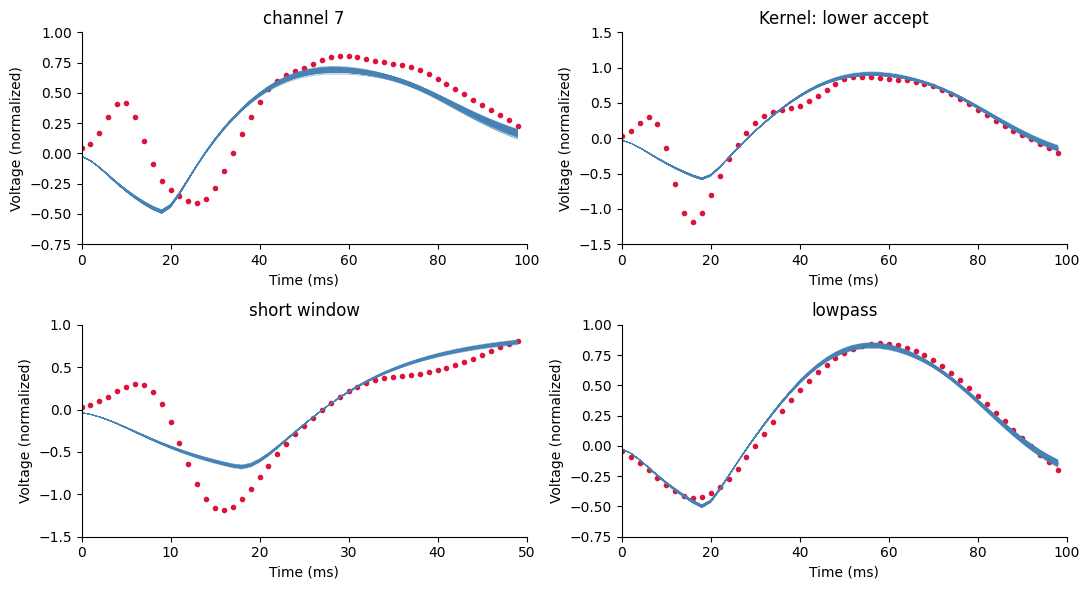

In [35]:
n_cfgs = len(sweep_configs)
fig, axes = plt.subplots(int(np.ceil(n_cfgs / 2)), 2, figsize=(11, 3 * int(np.ceil(n_cfgs / 2))))
axes = axes.flatten()

for ax, cfg in zip(axes, sweep_configs):
    res = sweep_results[cfg['name']]
    plotting.plot_predictive_overlay(ax, res['data']['ts_obs'], res['data']['xpy_obs'], res['post_pred']['xpy_model'],
                                      title=cfg['name'], lw=0.2, xlim=cfg['window'])
    ax.get_legend().remove()
fig.tight_layout()
plt.show()

Channel 7 leads to a worse fit than channel 5.

Using the other Kernel leads to the same result.

Using a shorter time window doesn't really enhance the fit in the beginning.

Using a lowpass filter results in a way better fit, almost perfect.

## Fitting to condition-combined signals

This section pools the trial-averaged ERP across every subject within a condition (at the same `example_channel` used everywhere else in this notebook), giving one grand-average signal each for ketamine, propofol, sevoflurane, wake (across all sessions and trials), and all anesthesia combined (drug-agnostic), and fits the same g-only model to each. Keta (all subjects) is the exact same grand average already fit as the primary target earlier in this notebook, that result gets reused here instead of running NUTS on it a second time, wake (across all sessions) is genuinely new at this point.

Let's first plot these ERP's.

keta (all subjects): pooled 8 recordings
prop (all subjects): pooled 9 recordings
sevo (all subjects): pooled 10 recordings
wake (all subjects, all sessions): pooled 27 recordings
anesthesia (all drugs combined): pooled 27 recordings


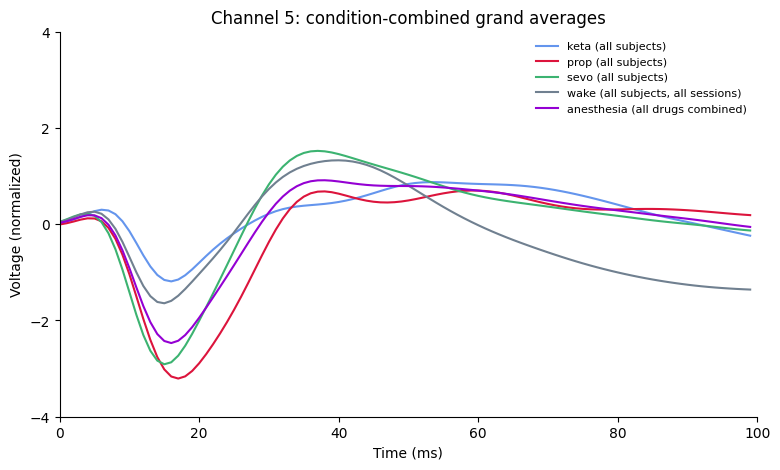

In [36]:
combined_targets = {
    'keta (all subjects)': [('keta', 'keta')],
    'prop (all subjects)': [('prop', 'prop')],
    'sevo (all subjects)': [('sevo', 'sevo')],
    'wake (all subjects, all sessions)': [('keta', 'wake'), ('prop', 'wake'), ('sevo', 'wake')],
    'anesthesia (all drugs combined)': [('keta', 'keta'), ('prop', 'prop'), ('sevo', 'sevo')],
}
combined_palette = {
    'keta (all subjects)': plotting.ANES_COLORS['keta'],
    'prop (all subjects)': plotting.ANES_COLORS['prop'],
    'sevo (all subjects)': plotting.ANES_COLORS['sevo'],
    'wake (all subjects, all sessions)': plotting.ANES_COLORS['wake'],
    'anesthesia (all drugs combined)': 'darkviolet',
}

combined_data = {}
for label, pairs in combined_targets.items():
    t_full, v_full, n_pooled = dat.combine_across_subjects(erp_datasets, pairs, example_channel)
    t, v, sigma_obs_cfg = mcmc.crop_after_sigma_obs(t_full, v_full)
    combined_data[label] = dict(time=t, values=v, n_pooled=n_pooled, sigma_obs=sigma_obs_cfg)
    print(f'{label}: pooled {n_pooled} recordings')

fig, ax = plt.subplots(figsize=(9, 5))
for label, d in combined_data.items():
    ax.plot(d['time'], d['values'], color=combined_palette[label], lw=1.5, label=label)
ax.set_xlabel('Time (ms)')
ax.set_ylabel('Voltage (normalized)')
ax.set_title(f'Channel {example_channel + 1}: condition-combined grand averages')
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(0, 100), ylim=(-4, 4))
ax.legend(frameon=False, fontsize=8)
plt.show()

Now we can perform the MCMC algorithm on them. The last fit of the 5 takes by far the longest, this is not a bug, this just means that the algorithm has a loot of trouble finding the good fits (This is also run on hard mode, so it takes approximatly 26 min, on easy mode it takes 3 min).

In [37]:
combined_settings = mcmc_settings(mode='hard', n_warmup=500, n_samples=1000, n_chains=4)

fit_targets = {label: d for label, d in combined_data.items() if label != 'keta (all subjects)'}
rng_key, *combined_keys = jax.random.split(rng_key, len(fit_targets) + 1)
combined_keys_iter = iter(combined_keys)

combined_results = {}
for label in tqdm(combined_targets, total=len(combined_targets), desc='Condition-combined fits'):
    if label == 'keta (all subjects)':
        # exact same grand average already fit as the primary target earlier in this notebook,
        # reuse that result instead of running NUTS on it a second time
        n_div = int(np.asarray(primary_mcmc.get_extra_fields()['diverging']).sum())
        combined_results[label] = dict(data=primary_data, post_pred=post_pred, sigma_obs=sigma_obs_avg,
                                        n_diverging=n_div, samples=primary_mcmc.get_samples(), az_obj=primary_az)
        print(f'{label:<38} sigma_obs={sigma_obs_avg:.3f}  divergences: {n_div}  (reused primary fit)')
        continue
    d = combined_data[label]
    key = next(combined_keys_iter)
    sigma_obs_cfg = d['sigma_obs']  # computed from the full pre-crop baseline when combined_data was built
    cfg_data = mcmc.make_data_dict(d['time'], d['values'], ds=ds)
    cfg_mcmc, cfg_elapsed = mcmc.run_nuts(model, cfg_data, prior_specs, key, sigma_obs=sigma_obs_cfg,
                                            kernel_kwargs=mcmc.kernel_preset('default'), verbose=False, **combined_settings)
    cfg_post_pred = mcmc.sample_posterior_predictive(model, cfg_data, prior_specs, cfg_mcmc.get_samples(), sigma_obs=sigma_obs_cfg)
    n_div = int(np.asarray(cfg_mcmc.get_extra_fields()['diverging']).sum())
    combined_results[label] = dict(data=cfg_data, post_pred=cfg_post_pred, sigma_obs=sigma_obs_cfg, n_diverging=n_div, samples=cfg_mcmc.get_samples(), az_obj=az.from_numpyro(cfg_mcmc))
    print(f'{label:<38} sigma_obs={sigma_obs_cfg:.3f}  divergences: {n_div}')

Condition-combined fits:   0%|          | 0/5 [00:00<?, ?it/s]

keta (all subjects)                    sigma_obs=0.039  divergences: 0  (reused primary fit)
prop (all subjects)                    sigma_obs=0.027  divergences: 0
sevo (all subjects)                    sigma_obs=0.037  divergences: 0
wake (all subjects, all sessions)      sigma_obs=0.013  divergences: 0
anesthesia (all drugs combined)        sigma_obs=0.010  divergences: 0


In [38]:
for label, res in combined_results.items():
    rhat_ds = az.rhat(res['az_obj'])
    print(label)
    for p in prm_names:
        vals = np.asarray(res['samples'][p]).ravel()
        print(f'  {p}: mean={vals.mean():.3f}  std={vals.std():.3f}  r_hat={float(rhat_ds[p].values):.3f}')

keta (all subjects)
  g_1: mean=0.058  std=0.048  r_hat=1.002
  g_2: mean=0.157  std=0.002  r_hat=1.001
  g_3: mean=0.114  std=0.034  r_hat=1.003
  g_4: mean=0.122  std=0.037  r_hat=1.004
prop (all subjects)
  g_1: mean=0.002  std=0.002  r_hat=1.001
  g_2: mean=0.211  std=0.001  r_hat=1.001
  g_3: mean=0.086  std=0.052  r_hat=1.000
  g_4: mean=0.076  std=0.050  r_hat=1.000
sevo (all subjects)
  g_1: mean=0.002  std=0.002  r_hat=1.002
  g_2: mean=0.230  std=0.002  r_hat=1.002
  g_3: mean=0.099  std=0.036  r_hat=1.006
  g_4: mean=0.110  std=0.039  r_hat=1.006
wake (all subjects, all sessions)
  g_1: mean=0.001  std=0.001  r_hat=1.001
  g_2: mean=0.067  std=0.000  r_hat=1.002
  g_3: mean=0.145  std=0.013  r_hat=1.002
  g_4: mean=0.325  std=0.029  r_hat=1.002
anesthesia (all drugs combined)
  g_1: mean=0.000  std=0.000  r_hat=1.006
  g_2: mean=0.202  std=0.000  r_hat=1.003
  g_3: mean=0.103  std=0.042  r_hat=1.006
  g_4: mean=0.098  std=0.041  r_hat=1.006


And we can plot the fits from the posterior.

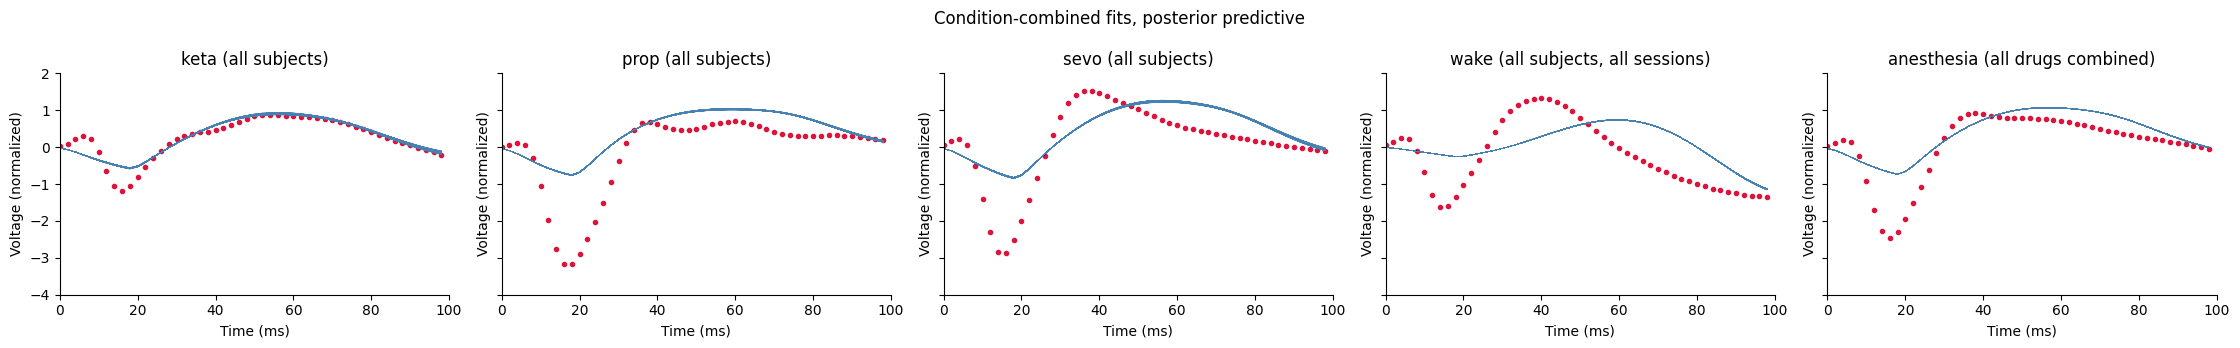

In [39]:
fig, axes = plt.subplots(1, len(combined_results), figsize=(4.5 * len(combined_results), 3.5), sharey=True)
for ax, (label, res) in zip(axes, combined_results.items()):
    plotting.plot_predictive_overlay(ax, res['data']['ts_obs'], res['data']['xpy_obs'], res['post_pred']['xpy_model'],
                                      title=label, lw=0.2, xlim=(0, 100), ylim=(-4, 2), yticks=np.arange(-4, 3, 1))
    ax.get_legend().remove()
fig.suptitle('Condition-combined fits, posterior predictive')
fig.tight_layout()
plt.show()

These different fits don't look great (except for keta). They also all look alike, but that's not true as you can see below:

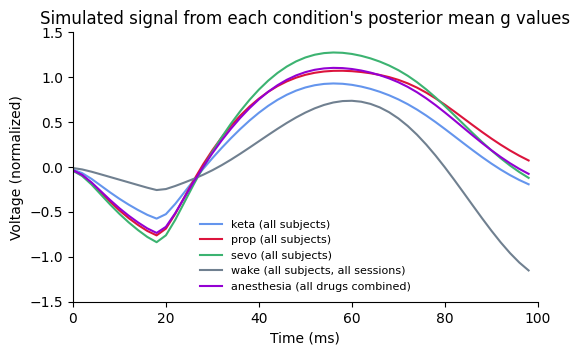

In [50]:
condition_means = {
    'keta (all subjects)': {'g_1': 0.058, 'g_2': 0.157, 'g_3': 0.114, 'g_4': 0.122},
    'prop (all subjects)': {'g_1': 0.002, 'g_2': 0.211, 'g_3': 0.086, 'g_4': 0.076},
    'sevo (all subjects)': {'g_1': 0.002, 'g_2': 0.230, 'g_3': 0.099, 'g_4': 0.110},
    'wake (all subjects, all sessions)': {'g_1': 0.001, 'g_2': 0.067, 'g_3': 0.145, 'g_4': 0.325},
    'anesthesia (all drugs combined)': {'g_1': 0.000, 'g_2': 0.202, 'g_3': 0.103, 'g_4': 0.098},
}
condition_colors = {
    'keta (all subjects)': plotting.ANES_COLORS['keta'],
    'prop (all subjects)': plotting.ANES_COLORS['prop'],
    'sevo (all subjects)': plotting.ANES_COLORS['sevo'],
    'wake (all subjects, all sessions)': plotting.ANES_COLORS['wake'],
    'anesthesia (all drugs combined)': 'darkviolet',
}

fig, ax = plt.subplots(figsize=(6, 3.5))
for label, free_params in condition_means.items():
    trace = mcmc.simulate_on_data_grid(primary_data, free_params)
    ax.plot(primary_data['ts_obs'], trace, color=condition_colors[label], lw=1.5, label=label)
ax.set_xlabel('Time (ms)')
ax.set_ylabel('Voltage (normalized)')
ax.set_title('Simulated signal from each condition\'s posterior mean g values')
ax.legend(frameon=False, fontsize=8)
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(0, 100))
plt.show()

And now we can plot the posteriors across the pooled fits.

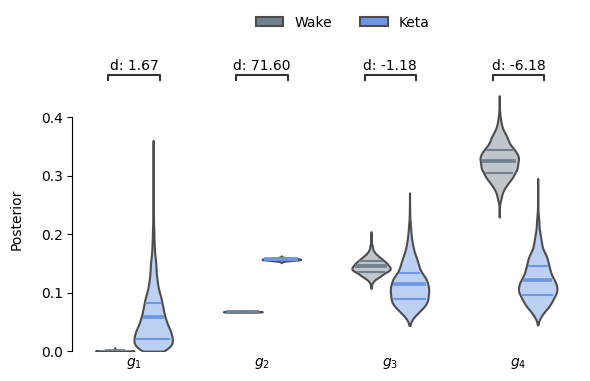

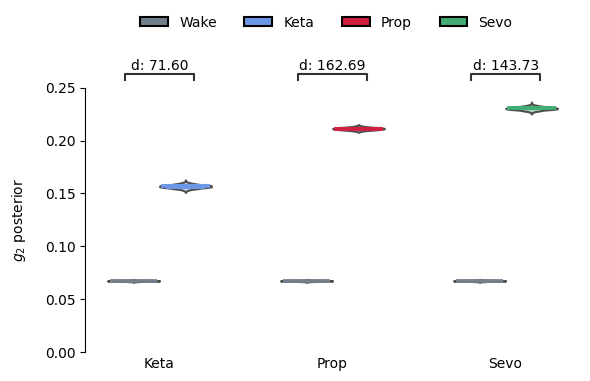

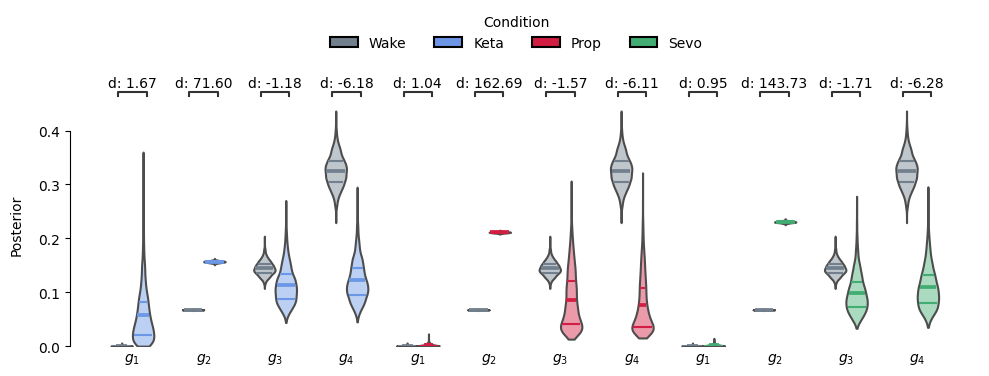

In [40]:
param_labels = {p: f'${p}$' for p in prm_names}
theta_rows = []
for anes_key in ['keta', 'prop', 'sevo']:
    for condition, label in [('wake', 'wake (all subjects, all sessions)'), (anes_key, f'{anes_key} (all subjects)')]:
        samples = combined_results[label]['samples']
        for p in prm_names:
            for val in np.asarray(samples[p]).ravel():
                theta_rows.append(dict(dataset=anes_key, condition=condition, parameter=p,
                                        theta_label=param_labels[p], value=val))
theta_df = pd.DataFrame(theta_rows)
dataset_to_plot = 'keta'
sel_param = 'g_2'

posterior_ylim = (0, 0.45)
posterior_yticks = (0, 0.1, 0.2, 0.3, 0.4)

fig1, ax1 = plt.subplots(figsize=(6, 4))
plotting.plot_single_dataset_comparison(fig1, ax1, theta_df, dataset_to_plot, plotting.DATASET_PALETTES[dataset_to_plot],
                                         lw=1.5, legend=True, saturation=0.9, custom_labels=list(param_labels.values()),
                                         ylabel='Posterior', width=0.6, labelpad=12, lgd_loc=(0.35, 1.2),
                                         theta_column='theta_label', y_lim=posterior_ylim, y_ticks=posterior_yticks)
fig2, ax2 = plt.subplots(figsize=(6, 4))
plotting.plot_parameter_across_datasets(fig2, ax2, theta_df, param_labels[sel_param], ['keta', 'prop', 'sevo'], plotting.DATASET_PALETTES,
                                         lw=1.5, legend=True, saturation=0.9,
                                         ylabel=f'{param_labels[sel_param]} posterior',
                                         width=0.6, labelpad=12, lgd_loc=(0.1, 1.2), theta_column='theta_label',
                                         y_lim=(0, 0.25), y_ticks=(0, 0.05, 0.1, 0.15, 0.2, 0.25))
fig3, ax3 = plt.subplots(figsize=(10, 4))
plotting.plot_pooled_posteriors(fig3, ax3, theta_df, ['keta', 'prop', 'sevo'], plotting.DATASET_PALETTES, lw=1.5, legend=True,
                                 saturation=0.9, ylabel='Posterior', width=0.6, lgd_loc=(0.28, 1.2),
                                 theta_column='theta_label', y_lim=posterior_ylim, y_ticks=posterior_yticks)
plt.show()

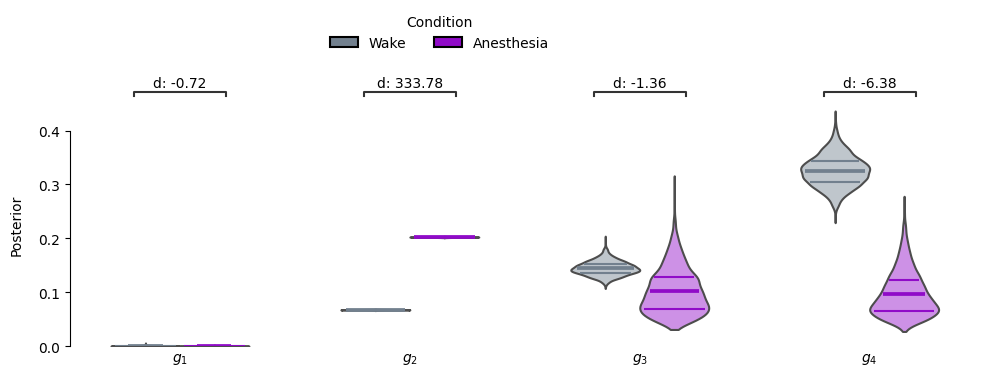

In [41]:
wake_anes_rows = []
for condition, label in [('wake', 'wake (all subjects, all sessions)'), ('anesthesia', 'anesthesia (all drugs combined)')]:
    samples = combined_results[label]['samples']
    for p in prm_names:
        for val in np.asarray(samples[p]).ravel():
            wake_anes_rows.append(dict(dataset='anesthesia', condition=condition, parameter=p,
                                        theta_label=param_labels[p], value=val))
wake_anes_df = pd.DataFrame(wake_anes_rows)
anes_combined_palette = {'anesthesia': {'wake': plotting.ANES_COLORS['wake'], 'anesthesia': 'darkviolet'}}

wake_anes_ylim = (0, 0.45)
wake_anes_yticks = (0, 0.1, 0.2, 0.3, 0.4)


fig4, ax4 = plt.subplots(figsize=(10, 4))
plotting.plot_pooled_posteriors(fig4, ax4, wake_anes_df, ['anesthesia'], anes_combined_palette, lw=1.5, legend=True,
                                 saturation=0.9, ylabel='Posterior', width=0.6, lgd_loc=(0.28, 1.2),
                                 theta_column='theta_label', y_lim=wake_anes_ylim, y_ticks=wake_anes_yticks)
plt.show()

## Fitting a more specific ERP

Everything above fits the pooled grand average, averaged across every subject's recording. This section goes the other way and fits more specific signals: first for one particular subject (`example_subject`) and then for one particular subject and trial (`example_subject` and `example_trial`).

This last ERP is loaded from Notebook 1's trial-resolved output (`{anes}_single_trials.nc`). Averaging suppresses a lot of trial-to-trial noise, real single trials look considerably rougher, so this is a test to see if the algorithm still works in this case.

`sigma_obs` gets re-estimated from each trace's own baseline rather than reusing the grand average's value, the single trial's actual observation noise is substantially higher than either trial-averaged value.

First we introduce the trial-averaged example subject ERP and calculate its sigma.

In [42]:
example_subject = 'j12' 

da_subj_avg = erp_datasets[example_anes].sel(subject=example_subject, condition='keta', region=example_channel)
subj_avg_time_full = da_subj_avg['time'].to_numpy() * 1000  # .nc time coord is in seconds, everywhere else works in ms
subj_avg_values_full = da_subj_avg.to_numpy()
subj_avg_time, subj_avg_values, sigma_obs_subj_avg = mcmc.crop_after_sigma_obs(subj_avg_time_full, subj_avg_values_full)
print(sigma_obs_subj_avg)

0.08216453583717091


Now we do the same for the trial-resolved example subject ERP.

In [43]:
trial_datasets = {example_anes: xr.load_dataarray(os.path.join(PROCESSED_DIR, f'{example_anes}_single_trials.nc'))}

# one single trial picked at random
n_trials_available = trial_datasets[example_anes].sizes['trial']
trial_rng = np.random.default_rng(7)
example_trial = int(trial_rng.integers(0, n_trials_available))

da_trial = trial_datasets[example_anes].sel(subject=example_subject, condition='keta', region=example_channel).isel(trial=example_trial)
trial_time_full = da_trial['time'].to_numpy() * 1000
trial_values_full = da_trial.to_numpy()
trial_time, trial_values, sigma_obs_trial = mcmc.crop_after_sigma_obs(trial_time_full, trial_values_full)

print(sigma_obs_trial)

0.11229489495806284


The trial resolved sigma is indeed larger than the trial averaged sigma.

Now we can plot both signals.

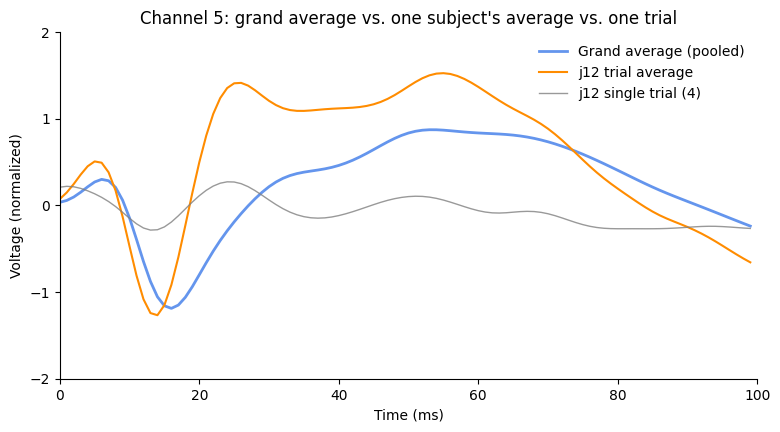

In [44]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(keta_time, keta_values, color=plotting.ANES_COLORS['keta'], lw=2, label='Grand average (pooled)')
ax.plot(subj_avg_time, subj_avg_values, color='darkorange', lw=1.5, label=f'{example_subject} trial average')
ax.plot(trial_time, trial_values, color='gray', lw=1, alpha=0.8, label=f'{example_subject} single trial ({example_trial})')
ax.set_xlabel('Time (ms)')
ax.set_ylabel('Voltage (normalized)')
ax.set_title(f"Channel {example_channel + 1}: grand average vs. one subject's average vs. one trial")
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(0, 100), ylim=(-2, 2))
ax.legend(frameon=False)
plt.show()

Given these ERP's, we can start the MCMC algorithm.

In [45]:
specific_targets = {
    f'{example_subject} trial average': dict(time=subj_avg_time, values=subj_avg_values, sigma_obs=sigma_obs_subj_avg),
    f'{example_subject} single trial ({example_trial})': dict(time=trial_time, values=trial_values, sigma_obs=sigma_obs_trial),
}

specific_settings = mcmc_settings(mode='easy', n_warmup=50, n_samples=50, n_chains=4)

rng_key, *specific_keys = jax.random.split(rng_key, len(specific_targets) + 1)

specific_results = {}
for (label, d), key in tqdm(zip(specific_targets.items(), specific_keys), total=len(specific_targets), desc='Specific ERP fits'):
    sigma_obs_cfg = d['sigma_obs']
    cfg_data = mcmc.make_data_dict(d['time'], d['values'], ds=ds)
    cfg_mcmc, cfg_elapsed = mcmc.run_nuts(model, cfg_data, prior_specs, key, sigma_obs=sigma_obs_cfg,
                                            kernel_kwargs=mcmc.kernel_preset('default'), verbose=False, **specific_settings)
    cfg_post_pred = mcmc.sample_posterior_predictive(model, cfg_data, prior_specs, cfg_mcmc.get_samples(), sigma_obs=sigma_obs_cfg)
    n_div = int(np.asarray(cfg_mcmc.get_extra_fields()['diverging']).sum())
    specific_results[label] = dict(data=cfg_data, post_pred=cfg_post_pred, sigma_obs=sigma_obs_cfg, n_diverging=n_div)
    print(f'{label:<38} sigma_obs={sigma_obs_cfg:.3f}  divergences: {n_div}')

Specific ERP fits:   0%|          | 0/2 [00:00<?, ?it/s]

j12 trial average                      sigma_obs=0.082  divergences: 0
j12 single trial (4)                   sigma_obs=0.112  divergences: 9


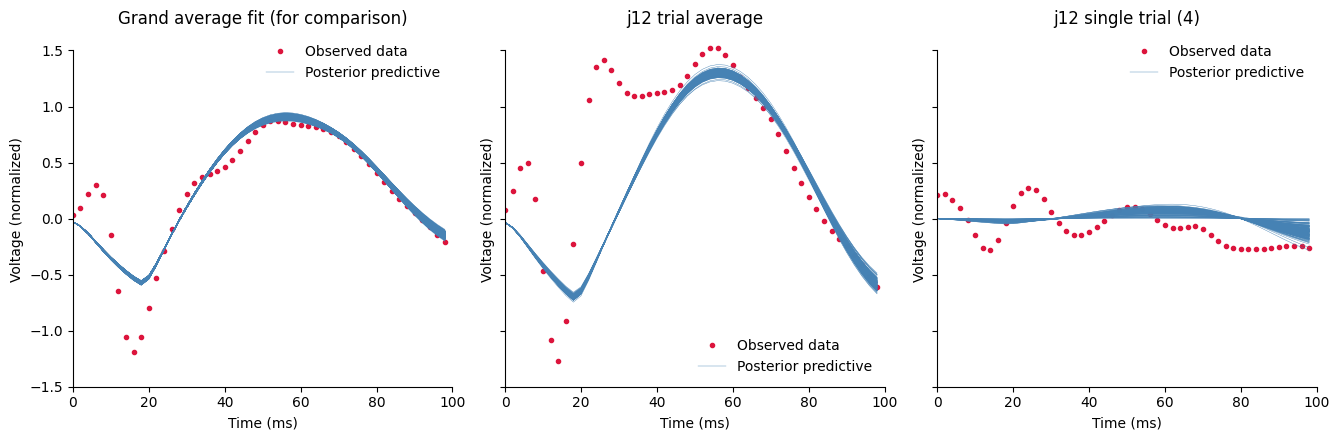

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.5), sharey=True)
plotting.plot_predictive_overlay(axes[0], primary_data['ts_obs'], primary_data['xpy_obs'], post_pred['xpy_model'],
                                  title='Grand average fit (for comparison)', xlim=(0, 100))
for ax, (label, res) in zip(axes[1:], specific_results.items()):
    plotting.plot_predictive_overlay(ax, res['data']['ts_obs'], res['data']['xpy_obs'], res['post_pred']['xpy_model'],
                                      title=label, xlim=(0, 100))
fig.tight_layout()
plt.show()

## Wrap-up

A few remarks and limitations worth keeping in mind:

- Fitting the full waveform (instead of a summary statistic like Notebook 3's PCIst) means NUTS has to explain every timepoint directly, which is a stricter test but also a slower one, and it shows: the primary fit (keta, channel 5) converges cleanly (R-hat 1.00, zero divergences) and tracks the main peak well, but misses the sharp early dip in the data.
- The channel, window, and kernel sweep didn't fix that early mismatch, but a lowpass filter almost did, so a good chunk of the leftover error looks like high frequency detail the model isn't built to capture, not a sampler or prior problem.
- Letting all 10 parameters vary instead of just the 4 gain parameters gives a noticeably better fit, but this notebook sticks to the g-only scope everywhere else, to stay comparable with Notebook 3 and to keep the results physically interpretable.
- The condition-combined fits all converge cleanly too (R-hat close to 1, zero divergences everywhere), but the visual fit quality varies a lot: keta looks good, propofol, sevoflurane, wake and the pooled anesthesia average all clearly miss that same early dip.
- Posterior separations between wake and anesthesia come out very large for some parameters, but the exact numbers (Cohen's d in the dozens or hundreds) shouldn't be taken at face value, they're inflated by the fact that a single pooled trace gives an extremely narrow, overconfident posterior with no trial or subject variability built in. We treat this as "clearly separated," not as a literal effect size.

Main result from the condition-combined fits: the g-only model was fit separately to the grand average of each condition (keta, prop, sevo, wake, and all anesthesia pooled). Across all of them, $g_2$ comes out consistently higher under every anesthetic than under wake, and $g_4$ comes out consistently higher under wake than under any anesthetic. $g_1$ and $g_3$ don't show a clear, consistent pattern. These same condition-combined grand averages are fit again in Notebook 3 with SBI, that comparison is left for Notebook 3 itself.

Time to run: approx 35 min (if using the original combination of easy and hard mode)